<a href="https://colab.research.google.com/github/missytfnov/Hello-World/blob/master/PBA_Sentiment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install google-play-scraper Sastrawi catboost pandas nltk scikit-learn statsmodels matplotlib seaborn numpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.1 MB/s eta 0:00:00


In [2]:
# from google_play_scraper import reviews, Sort, app as get_app_info
import pandas as pd
import json
import re
import nltk
import sklearn
from nltk.tokenize import word_tokenize
import unicodedata
from sklearn.feature_extraction.text import TfidfVectorizer
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from statsmodels.stats.inter_rater import aggregate_raters, fleiss_kappa
from sklearn.model_selection import train_test_split
from catboost import CatBoostClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
import seaborn as sns
import numpy as np
import os

<h1>Scraping Data</h1>

In [3]:
# app_id = "com.telkomsel.telkomselcm"
# jumlah_ulasan = 500
# tahun = 2026

In [4]:
# info = get_app_info(app_id, lang="id", country="id")
# hasil, _ = reviews(
#     app_id,
#     lang='id',  # Bahasa Indonesia
#     country='id',  # Indonesia
#     sort=Sort.NEWEST,  # Mengambil ulasan terbaru
#     count=jumlah_ulasan,  # Jumlah ulasan yang diambil
# )

In [5]:
# df_raw = pd.DataFrame(hasil)[["reviewId", "userName", "content", "score", "at", "reviewCreatedVersion"]]
# df_raw.columns = ["id_ulasan", "nama_pengguna", "ulasan", "rating", "tanggal", "versi_aplikasi_ulasan"]
# df_raw["tanggal"] = pd.to_datetime(df_raw["tanggal"])

In [6]:
# df = df_raw[df_raw['tanggal'].dt.year == tahun].copy()

In [7]:
# nama_file = f"ulasan_mytelkom_{tahun}.csv"
# df.to_csv(nama_file, index=False, encoding='utf-8-sig')

<h1>Data Load</h1>

In [8]:
SHEET_ID = "1JVpzO2-EAivK-HwRGoiLHcOTJWzX94UV1T1y1Xz-7Jg"
GID = "1412720530"
URL_SHEET = f"https://docs.google.com/spreadsheets/d/{SHEET_ID}/export?format=csv&gid={GID}"
df = pd.read_csv(URL_SHEET)
df["ulasan"] = df["ulasan"].fillna("").astype(str)   # avoid errors on empty reviews
df.to_csv("ulasan_mytelkom_2026.csv", index=False, encoding="utf-8-sig")
print(f"Loaded {len(df)} rows")
print(df.columns.tolist())
df.head()

Loaded 500 rows
['id_ulasan', 'nama_pengguna', 'ulasan', 'rating', 'tanggal', 'versi_aplikasi_ulasan', 'Bagus', 'Daniel', 'Liza', 'Cila', 'Missy', 'Summary']


,id_ulasan,nama_pengguna,ulasan,rating,tanggal,versi_aplikasi_ulasan,Bagus,Daniel,Liza,Cila,Missy,Summary
0,c0189ec1-51f2-4d64-a974-a23f6e953702,Rizaldy Rais,jaringan Telkomsel wilayah Agam timur sangat l...,1,2026-09-17 12:47:48,9.3.2000,negative,negative,negative,negative,negative,negative
1,32c878a1-25c9-46c8-a645-a506f422f236,Darwin Ipin,mantap,5,2026-09-17 12:46:36,9.3.2000,positive,positive,positive,positive,positive,positive
2,46728e9d-95a0-42cc-a3d7-79727e140e24,Endang Setiasih,Suka kluar sendiri padahal hp ram 8 aneh nih a...,1,2026-09-17 12:46:30,9.3.2000,negative,negative,negative,negative,negative,negative
3,3a761f28-8040-4395-ba2f-a44f6f8c41b6,Randi Priyanto,maaf ya saya kurangin dulu bintang nya soal ny...,3,2026-09-17 12:46:28,8.6.2002,negative,negative,negative,negative,negative,negative
4,80a08cf2-7248-4efa-9016-95681b423214,eko z,sinyal lemot sering keluar aplikasi sendiri ma...,1,2026-09-17 12:45:37,9.2.2001,negative,negative,negative,negative,negative,negative


<h1>Tokenize</h1>

In [9]:
INPUT_PATH = "ulasan_mytelkom_2026.csv"
OUTPUT_PATH = "ulasan_tokenized_nltk.json"
nltk.download("punkt")
nltk.download("punkt_tab")
ANGKA = {"satu": "1", "dua": "2", "tiga": "3", "empat": "4", "lima": "5"}
def gabung_bintang(teks):
    pola_angka = r"(satu|dua|tiga|empat|lima|[1-5])"
    teks = re.sub(rf"\b{pola_angka}\s*bintang\b",lambda m: "bintang_" + ANGKA.get(m.group(1), m.group(1)), teks)
    teks = re.sub(rf"\bbintang\s*{pola_angka}\b",lambda m: "bintang_" + ANGKA.get(m.group(1), m.group(1)), teks)
    return teks

def tokenize(teks):
    teks = str(teks).lower()
    teks = gabung_bintang(teks)
    for tanda in [".", ",", ";", ":", "?", "!"]:
        teks = teks.replace(tanda, " ")
    return word_tokenize(teks)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [10]:
df = pd.read_csv(INPUT_PATH)
df["ulasan"] = df["ulasan"].fillna("").astype(str)
df["tokens"] = df["ulasan"].apply(tokenize)
df.to_json(OUTPUT_PATH, orient="records", force_ascii=False, indent=2)
print(f"NLTK tokenize DONE: {OUTPUT_PATH}")

NLTK tokenize DONE: ulasan_tokenized_nltk.json


<h1>Normalization</h1>

In [11]:
INPUT_PATH_NORM = "ulasan_tokenized_nltk.json"
OUTPUT_PATH_NORM = "ulasan_normalized.json"

In [12]:
URL_KAMUS = "https://raw.githubusercontent.com/nasalsabila/kamus-alay/master/colloquial-indonesian-lexicon.csv"

try:
    df_kamus = pd.read_csv(URL_KAMUS).dropna(subset=["slang", "formal"])
    kamus_slang = dict(zip(
        df_kamus["slang"].astype(str).str.lower().str.strip(),
        df_kamus["formal"].astype(str).str.lower().str.strip()
    ))
    print(f"Kamus alay dimuat: {len(kamus_slang)} entri")
except Exception as e:
    kamus_slang = {}
    print(f"Gagal memuat kamus online ({e}), pakai kamus manual saja")

Kamus alay dimuat: 4330 entri


In [13]:
kamus_manual = {
    "gk": "tidak", "ga": "tidak", "gak": "tidak", "ngak": "tidak", "nggak": "tidak", "tdk": "tidak",
    "yg": "yang", "udh": "sudah", "udah": "sudah", "sdh": "sudah", "blm": "belum", "belom": "belum",
    "bgt": "banget", "sy": "saya", "aq": "aku", "gw": "saya", "gue": "saya",
    "dgn": "dengan", "dg": "dengan", "utk": "untuk", "tp": "tapi", "krn": "karena", "karna": "karena",
    "trs": "terus", "jd": "jadi", "jg": "juga", "lg": "lagi", "bs": "bisa", "bsa": "bisa", "sm": "sama",
    "knp": "kenapa", "gmn": "bagaimana", "gimana": "bagaimana", "kalo": "kalau", "klo": "kalau",
    "dr": "dari", "org": "orang", "hrs": "harus", "msh": "masih", "aja": "saja", "aj": "saja",
    "pake": "pakai", "pakek": "pakai",
    "apk": "aplikasi", "app": "aplikasi", "apl": "aplikasi", "tsel": "telkomsel",
    "kouta": "kuota", "qouta": "kuota", "signal": "sinyal", "singnal": "sinyal",
    "min": "admin", "mimin": "admin",
    "gpp": "tidak apa apa", "gapapa": "tidak apa apa", "mantul": "mantap betul",
    "makasih": "terima kasih", "mksh": "terima kasih", "trims": "terima kasih", "thx": "terima kasih", "tq": "terima kasih",
    "ok": "oke", "okay": "oke", "bgs": "bagus", "lemot": "lambat", "lelet": "lambat",
    "erorr": "error"
}
kamus_manual.update({"pket":"paket","eror":"error","ngetod":"ngentod","taaiiiiiiii":"tahi","pol":"banget","pelitt":"pelit","anjig":"anjing","pukii":"puki","provder":"provider","njingg":"anjing"
,"berberapa":"beberapa","loadingnya":"loading","bitang":"bintang","sangtlah":"sangat","semuaa":"semua","jaringannya":"jaringan","indihomenya":"indihome","ajg":"anjing","relog":"login","sebeluh":"sebelah","kont0l":"kontol","byar":"bayar","fix":"perbaiki","mausuk":"masuk",
"mahalin":"mahal","stbill":"stabil","anying":"anjing","gbsa":"tidak","desedot":"disedot","gblok":"goblok","bug":"masalah","mura":"murah","mkasih":"terima kasih","lag":"lambat","samsek":"sama sekali"})
kamus_manual.update({
    "enggak": "tidak", "engga": "tidak", "ngga": "tidak", "nggak": "tidak", "kagak": "tidak", "kaga": "tidak", "engak": "tidak",
    "gajelas": "tidak jelas", "gabisa": "tidak bisa", "gada": "tidak ada", "gaada": "tidak ada", "gamau": "tidak mau", "gapernah": "tidak pernah",
    "mb": "mb", "gb": "gb", # Override "mb" in case it was mapped to "mbak"
    "kelemotan": "lambat", "lemotnya": "lambat", "lemoth": "lambat",
    "kuoto": "kuota", "membatu": "membantu", "memuaskn": "memuaskan", "bsgus": "bagus", "sangst": "sangat",
})
kamus_normalisasi = {**kamus_slang, **kamus_manual}
print(f"Total kamus normalisasi: {len(kamus_normalisasi)} entri")

Total kamus normalisasi: 4397 entri


In [14]:
kamus_emoji = {
    "👍": " bagus ", "👎": " jelek ", "🥰": " suka ", "😍": " suka ", "❤": " suka ",
    "🙏": " terima kasih ", "😡": " marah ", "🤬": " marah ", "😭": " sedih ",
    "😞": " kecewa ", "🤢": " jijik ",
    "🙄": " kesal ", "😤": " kesal ", "😠": " marah ", "😢": " sedih ", "💩": " jelek ",
    "😊": " senang ", "😁": " senang ", "🔥": " mantap ", "💯": " mantap ",
    # 😂 sengaja tidak dipetakan: di ulasan keluhan sering dipakai untuk sarkasme
}
print(f"Kamus emoji dimuat: {len(kamus_emoji)} entri")

Kamus emoji dimuat: 20 entri


In [15]:
df_tokenized = pd.read_json(INPUT_PATH_NORM, orient="records")
def normalize_token(tokens):
    normalized_tokens_list = []
    for token in tokens:
        token = unicodedata.normalize("NFKC", token).lower()
        for emoji_char, replacement_word in kamus_emoji.items():
            token = token.replace(emoji_char, replacement_word)
        token = re.sub(r'http\S+|www\S+', '', token)
        token = token.replace('-', ' ')
        token = re.sub(r'[^a-z0-9_\s]', ' ', token)
        token = re.sub(r'\s+', ' ', token).strip()
        token = re.sub(r'([a-z])\1{2,}', r'\1', token)
        sub_tokens = token.split()
        processed_sub_tokens = []
        for sub_token in sub_tokens:
            match_repeated_word = re.match(r'([a-z]{2,})2$', sub_token)
            if match_repeated_word:
                base_word = match_repeated_word.group(1)
                processed_sub_tokens.extend([base_word, base_word])
                continue
            first_normalized = kamus_normalisasi.get(sub_token, sub_token)
            for part in first_normalized.split():
                processed_sub_tokens.append(kamus_normalisasi.get(part, part))
        normalized_tokens_list.extend([t for t in processed_sub_tokens if t])
    return normalized_tokens_list
df_tokenized["tokens_asli"] = df_tokenized["tokens"]
df_tokenized["tokens"] = df_tokenized["tokens"].apply(normalize_token)
df_tokenized.to_json(OUTPUT_PATH_NORM, orient="records", force_ascii=False, indent=2)
print(f"Normalization DONE: {OUTPUT_PATH_NORM}")

Normalization DONE: ulasan_normalized.json


<h1>Stopword</h1>

In [16]:
INPUT_PATH_STOPWORD = "ulasan_normalized.json"
OUTPUT_PATH_STOPWORD = "ulasan_filtered.json"

In [17]:
factory = StopWordRemoverFactory()
stopwords_sastrawi = factory.get_stop_words()

In [18]:
stopwords_sastrawi = set(stopwords_sastrawi)
stopwords_sastrawi -= {"tidak", "belum", "bukan", "jangan","bisa", "tapi", "namun", "tanpa", "tolong","dapat", "harus", "masih", "hanya", "agak"}

In [19]:
if not os.path.exists(INPUT_PATH_STOPWORD):
    raise FileNotFoundError(f"Error: File '{INPUT_PATH_STOPWORD}' not found. Please ensure normalization is done and the file exists.")
with open(INPUT_PATH_STOPWORD, "r", encoding="utf-8") as f:
    data_ulasan = json.load(f)
for item in data_ulasan:
    if "tokens" in item:
        tokens_awal = item["tokens"]
        tokens_bersih = [kata for kata in tokens_awal if kata.lower() not in stopwords_sastrawi]
        item["filtered_tokens"] = tokens_bersih
with open(OUTPUT_PATH_STOPWORD, "w", encoding="utf-8") as f:
    json.dump(data_ulasan, f, ensure_ascii=False, indent=2)
print(f"stopword DONE: {OUTPUT_PATH_STOPWORD}")

stopword DONE: ulasan_filtered.json


<h1>Stemming</h1>

In [20]:
INPUT_PATH_FILTERED = "ulasan_filtered.json"
OUTPUT_PATH_FILTERED = "ulasan_Clean.json"

In [21]:
with open(INPUT_PATH_FILTERED, "r", encoding="utf-8") as f:
    data = json.load(f)
factory = StemmerFactory()
stemmer = factory.create_stemmer()

In [22]:
stem_cache = {}
stem_manual = {
    "berikan": "beri", "kurangin": "kurang", "pengecekan": "cek",
    "sebelumnya": "sebelum", "perusahan": "perusahaan", "perusahaan": "perusahaan",
    "bekasi": "bekasi", "bali": "bali", "maluku": "maluku",
}
def get_token_key(item):
    for key in ["filtered_tokens", "tokens_filtered", "tokens"]:
        if key in item:
            return key
    raise KeyError(f"Key token tidak ditemukan: {list(item.keys())}")
def stem_word(word):
    if word in stem_manual:
        return stem_manual[word]
    if "_" in word or any(ch.isdigit() for ch in word):
        return word
    if word not in stem_cache:
        stem_cache[word] = stemmer.stem(word)
    return stem_cache[word]

In [23]:
if "stem_cache" not in globals():
    stem_cache = {}

cleaned_data = []
for item in data:
    token_key = get_token_key(item)
    stemmed = [s for s in (stem_word(t) for t in item[token_key]) if s.strip()]
    cleaned_data.append({
        **{k: v for k, v in item.items() if k != token_key},
        "tokens_stemmed": stemmed,
        "ulasan_clean": " ".join(stemmed),
    })

In [24]:
with open(OUTPUT_PATH_FILTERED, "w", encoding="utf-8") as f:
    json.dump(cleaned_data, f, ensure_ascii=False, indent=2)

<h1>Imbalance Analysis</h1>

In [25]:
target = pd.DataFrame(cleaned_data)
target["ulasan_clean"] = target["ulasan_clean"].fillna("").astype(str)
kosong = target["ulasan_clean"].str.strip() == ""
print(f"Ulasan kosong dibuang: {kosong.sum()}")
target = target[~kosong].reset_index(drop=True)
label_map = {"negative": -1, "neutral": 0, "positive": 1}
print(target["Summary"].value_counts(dropna=False))
target["target"] = target["Summary"].astype(str).str.strip().str.lower().map(label_map)
print(f"Baris tanpa label valid dibuang: {target["target"].isna().sum()}")
target = target.dropna(subset=["target"]).reset_index(drop=True)
target["target"] = target["target"].astype(int)
print(f"Jumlah data untuk model: {len(target)}")

Ulasan kosong dibuang: 0
Summary
negative    353
positive     96
neutral      51
Name: count, dtype: int64
Baris tanpa label valid dibuang: 0
Jumlah data untuk model: 500


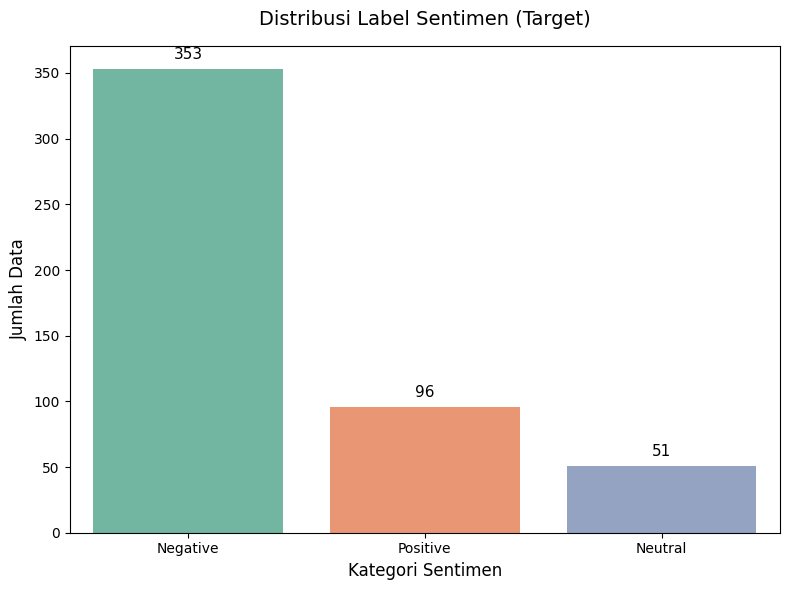

In [26]:
plt.figure(figsize=(8, 6))
kategori_counts = target["Summary"].str.strip().str.title().value_counts()
ax = sns.barplot(x=kategori_counts.index, y=kategori_counts.values, hue=kategori_counts.index, palette="Set2", legend=False)
plt.title("Distribusi Label Sentimen (Target)", fontsize=14, pad=15)
plt.xlabel("Kategori Sentimen", fontsize=12)
plt.ylabel("Jumlah Data", fontsize=12)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),ha='center', va='bottom', fontsize=11, color='black',xytext=(0, 5),textcoords='offset points')
plt.tight_layout()
plt.show()

<h3>Fleis-Kappa Analysis</h3>

In [27]:
df_label = pd.DataFrame(cleaned_data)
anotator = [c for c in ["Bagus", "Daniel", "Liza", "Cila", "Missy"] if c in df_label.columns]
lab = df_label[anotator].apply(lambda s: s.astype(str).str.strip().str.lower().map(label_map))
lab = lab.dropna().astype(int)
if len(anotator) >= 2 and len(lab) > 0:
    tabel, _ = aggregate_raters(lab.values)
    print(f"Fleiss' kappa ({len(anotator)} anotator, {len(lab)} ulasan): {fleiss_kappa(tabel):.4f}")
else:
    print("Kolom anotator tidak ditemukan atau labelnya tidak cocok dengan negative/neutral/positive.")

Fleiss' kappa (5 anotator, 500 ulasan): 0.8751


<h1>Train-Test Split</h1>

In [28]:
teks = target["ulasan_clean"]
y = target["target"]

teks_train_full, teks_test, y_train_full, y_test = train_test_split(
    teks, y, test_size=0.2, random_state=42, stratify=y
)
teks_train, teks_val, y_train, y_val = train_test_split(
    teks_train_full, y_train_full, test_size=0.15, random_state=42, stratify=y_train_full
)
print(f"train: {len(teks_train)} | val: {len(teks_val)} | test: {len(teks_test)}")

train: 340 | val: 60 | test: 100


<h1>Vectorization</h1>

<h3>TF-IDF Vectorization</h3>

In [29]:
# TF-IDF di-fit hanya pada data train. Bigram menjaga frasa seperti "tidak bagus".
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
X_train = vectorizer.fit_transform(teks_train).toarray()
X_val = vectorizer.transform(teks_val).toarray()
X_test = vectorizer.transform(teks_test).toarray()

print(X_train.shape, X_val.shape, X_test.shape)
print(vectorizer.get_feature_names_out()[:50])

(340, 728) (60, 728) (100, 728)
['10' '100' '11' '16' '188' '23' '28' '28 hari' '30' '30 hari' '3gb' '4g'
 '5g' '60' 'ada' 'admin' 'aduh' 'agak' 'akal' 'akhir' 'akses' 'aktif'
 'aktif paket' 'aktivitas' 'aku' 'aku beli' 'akun' 'akun sendiri' 'alas'
 'ampun' 'anak' 'aneh' 'anjing' 'anti' 'anti spam' 'apa' 'apa bagaimana'
 'apa coba' 'apa sih' 'apa telkomsel' 'aplikasi' 'aplikasi bayar'
 'aplikasi berat' 'aplikasi bisa' 'aplikasi buat' 'aplikasi buruk'
 'aplikasi error' 'aplikasi kalau' 'aplikasi lambat' 'aplikasi nya']


<h3>Bert Embedding Vectorization</h3>

In [30]:
import torch
import numpy as np
from transformers import AutoTokenizer, AutoModel
model_name = "indobenchmark/indobert-base-p1"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

def get_indobert_embeddings(text_list, batch_size=16):
    model.eval()
    embeddings = []

    for i in range(0, len(text_list), batch_size):
        batch_texts = text_list[i:i+batch_size]
        encoded_input = tokenizer(batch_texts, padding=True, truncation=True, max_length=128, return_tensors='pt').to(device)
        with torch.no_grad():
            output = model(**encoded_input)
            cls_embedding = output.last_hidden_state[:, 0, :]
            embeddings.append(cls_embedding.cpu().numpy())

    return np.vstack(embeddings)
teks_train_list = list(teks_train)
teks_val_list = list(teks_val)
teks_test_list = list(teks_test)

X_train_bert = get_indobert_embeddings(teks_train_list)
X_val_bert = get_indobert_embeddings(teks_val_list)
X_test_bert = get_indobert_embeddings(teks_test_list)

print(X_train_bert.shape, X_val_bert.shape, X_test_bert.shape)

config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

(340, 768) (60, 768) (100, 768)


<h3>Imbalance Handling With Class-Weight</h3>

In [31]:
classes = np.array([-1, 0, 1])
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)
class_weights = dict(zip(classes, weights))
print("Class weights:", class_weights)

Class weights: {np.int64(-1): np.float64(0.4722222222222222), np.int64(0): np.float64(3.238095238095238), np.int64(1): np.float64(1.7435897435897436)}


<h1>Modelling With Class-Weight</h1>

<h3>TF-IDF</h3>

In [32]:
#Catboost

model = CatBoostClassifier(
    loss_function="MultiClass",
    eval_metric="MultiClass",
    iterations=500,
    learning_rate=0.05,
    depth=8,
    class_weights=class_weights,
    random_seed=42,
    verbose=100,
    task_type="GPU",
)

model.fit(X_train,y_train,eval_set=(X_val, y_val),early_stopping_rounds=50)

y_pred = model.predict(X_test).ravel()

0:	learn: 1.0673560	test: 1.0692548	best: 1.0692548 (0)	total: 34.2ms	remaining: 17.1s
100:	learn: 0.3972722	test: 0.5419088	best: 0.5419088 (100)	total: 1.04s	remaining: 4.11s
200:	learn: 0.2883152	test: 0.4899969	best: 0.4899969 (200)	total: 1.92s	remaining: 2.85s
300:	learn: 0.2353609	test: 0.4718792	best: 0.4716724 (299)	total: 2.79s	remaining: 1.85s
400:	learn: 0.2036464	test: 0.4588821	best: 0.4588821 (400)	total: 3.65s	remaining: 902ms
499:	learn: 0.1801371	test: 0.4478369	best: 0.4466746 (483)	total: 4.51s	remaining: 0us
bestTest = 0.4466745921
bestIteration = 483
Shrink model to first 484 iterations.


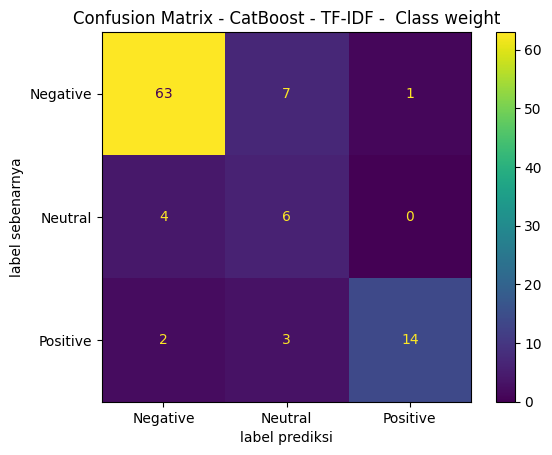

In [33]:
cm = confusion_matrix(y_test, y_pred, labels=[-1, 0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)
disp.plot()
plt.title("Confusion Matrix - CatBoost - TF-IDF -  Class weight")
plt.xlabel("label prediksi")
plt.ylabel("label sebenarnya")
plt.show()

In [34]:
print(classification_report(y_test, y_pred, labels=[-1, 0, 1],
                            target_names=["Negative", "Neutral", "Positive"], digits=4))

              precision    recall  f1-score   support

    Negative     0.9130    0.8873    0.9000        71
     Neutral     0.3750    0.6000    0.4615        10
    Positive     0.9333    0.7368    0.8235        19

    accuracy                         0.8300       100
   macro avg     0.7405    0.7414    0.7284       100
weighted avg     0.8631    0.8300    0.8416       100



In [35]:
#Logistic Regression
lr = LogisticRegression(max_iter=2000, class_weight="balanced")
lr.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=2000)

In [36]:
y_pred = lr.predict(X_test).ravel()

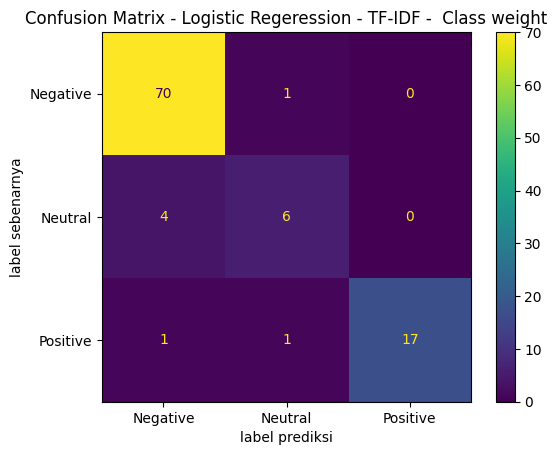

In [37]:
cm = confusion_matrix(y_test, y_pred, labels=[-1, 0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)
disp.plot()
plt.title("Confusion Matrix - Logistic Regeression - TF-IDF -  Class weight")
plt.xlabel("label prediksi")
plt.ylabel("label sebenarnya")
plt.show()

In [38]:
print(classification_report(y_test, y_pred, labels=[-1, 0, 1],
                            target_names=["Negative", "Neutral", "Positive"], digits=4))

              precision    recall  f1-score   support

    Negative     0.9333    0.9859    0.9589        71
     Neutral     0.7500    0.6000    0.6667        10
    Positive     1.0000    0.8947    0.9444        19

    accuracy                         0.9300       100
   macro avg     0.8944    0.8269    0.8567       100
weighted avg     0.9277    0.9300    0.9269       100



<h3>IndoBERT Embedding Vectorization</h3>

In [39]:
#Catboost
import shutil

model = CatBoostClassifier(
    loss_function="MultiClass",
    eval_metric="MultiClass",
    iterations=500,
    learning_rate=0.05,
    depth=8,
    class_weights=class_weights,
    random_seed=42,
    verbose=100,
    task_type="GPU",
)

model.fit(X_train_bert,y_train,eval_set=(X_val_bert, y_val),early_stopping_rounds=50)

y_pred = model.predict(X_test_bert).ravel()

0:	learn: 1.0547860	test: 1.0695602	best: 1.0695602 (0)	total: 42.5ms	remaining: 21.2s
100:	learn: 0.1356505	test: 0.5333186	best: 0.5333186 (100)	total: 4.13s	remaining: 16.3s
200:	learn: 0.0590775	test: 0.5035250	best: 0.5032487 (195)	total: 8.17s	remaining: 12.2s
300:	learn: 0.0361665	test: 0.4984205	best: 0.4983073 (296)	total: 12.2s	remaining: 8.08s
bestTest = 0.4983072969
bestIteration = 296
Shrink model to first 297 iterations.


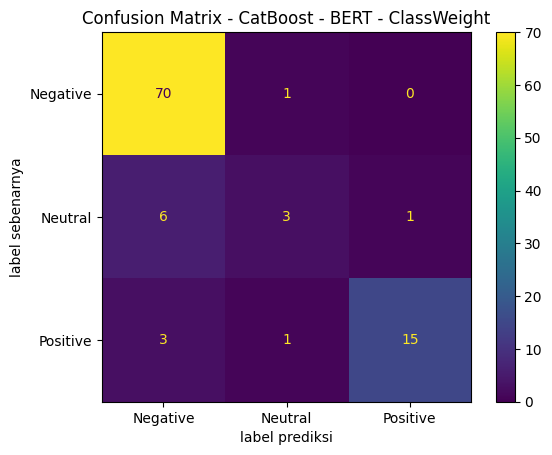

In [40]:
cm = confusion_matrix(y_test, y_pred, labels=[-1, 0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)
disp.plot()
plt.title("Confusion Matrix - CatBoost - BERT - ClassWeight")
plt.xlabel("label prediksi")
plt.ylabel("label sebenarnya")
plt.show()

In [41]:
print(classification_report(y_test, y_pred, labels=[-1, 0, 1],
                            target_names=["Negative", "Neutral", "Positive"], digits=4))

              precision    recall  f1-score   support

    Negative     0.8861    0.9859    0.9333        71
     Neutral     0.6000    0.3000    0.4000        10
    Positive     0.9375    0.7895    0.8571        19

    accuracy                         0.8800       100
   macro avg     0.8079    0.6918    0.7302       100
weighted avg     0.8672    0.8800    0.8655       100



In [42]:
#Logistic Regression
lr = LogisticRegression(max_iter=2000, class_weight="balanced")
lr.fit(X_train_bert, y_train)
y_pred = lr.predict(X_test_bert).ravel()

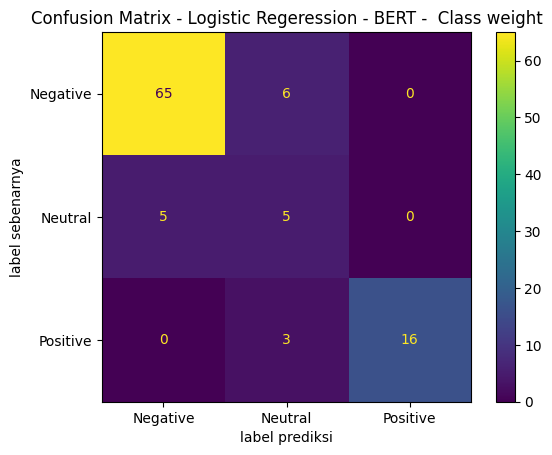

In [43]:
cm = confusion_matrix(y_test, y_pred, labels=[-1, 0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)
disp.plot()
plt.title("Confusion Matrix - Logistic Regeression - BERT -  Class weight")
plt.xlabel("label prediksi")
plt.ylabel("label sebenarnya")
plt.show()

In [44]:
print(classification_report(y_test, y_pred, labels=[-1, 0, 1],
                            target_names=["Negative", "Neutral", "Positive"], digits=4))

              precision    recall  f1-score   support

    Negative     0.9286    0.9155    0.9220        71
     Neutral     0.3571    0.5000    0.4167        10
    Positive     1.0000    0.8421    0.9143        19

    accuracy                         0.8600       100
   macro avg     0.7619    0.7525    0.7510       100
weighted avg     0.8850    0.8600    0.8700       100



<h1>Modelling Without Class-Weight</h1>

<h3>TF-IDF</h3>

In [45]:
#Catboost

model = CatBoostClassifier(
    loss_function="MultiClass",
    eval_metric="MultiClass",
    iterations=500,
    learning_rate=0.05,
    depth=8,
    random_seed=42,
    verbose=100,
    task_type="GPU",
)

model.fit(X_train,y_train,eval_set=(X_val, y_val),early_stopping_rounds=50)

y_pred = model.predict(X_test).ravel()

0:	learn: 1.0446770	test: 1.0492952	best: 1.0492952 (0)	total: 10.5ms	remaining: 5.22s
100:	learn: 0.3311240	test: 0.4388230	best: 0.4386286 (99)	total: 983ms	remaining: 3.88s
200:	learn: 0.2656303	test: 0.4230134	best: 0.4220609 (184)	total: 1.83s	remaining: 2.72s
300:	learn: 0.2181888	test: 0.4071930	best: 0.4069727 (299)	total: 2.69s	remaining: 1.78s
400:	learn: 0.1876477	test: 0.3994266	best: 0.3987583 (392)	total: 3.55s	remaining: 876ms
499:	learn: 0.1668796	test: 0.3932674	best: 0.3930089 (488)	total: 4.4s	remaining: 0us
bestTest = 0.3930088679
bestIteration = 488
Shrink model to first 489 iterations.


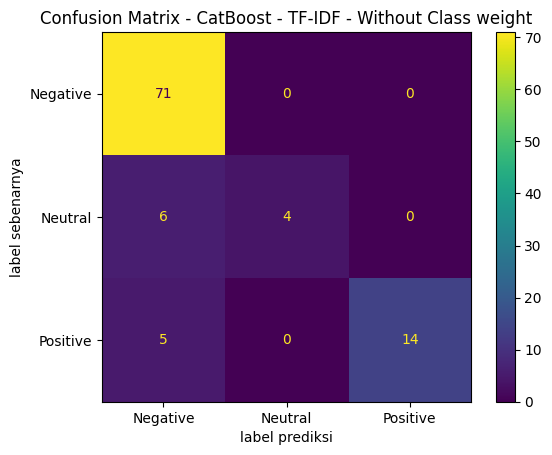

In [46]:
cm = confusion_matrix(y_test, y_pred, labels=[-1, 0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)
disp.plot()
plt.title("Confusion Matrix - CatBoost - TF-IDF - Without Class weight")
plt.xlabel("label prediksi")
plt.ylabel("label sebenarnya")
plt.show()

In [47]:
print(classification_report(y_test, y_pred, labels=[-1, 0, 1],
                            target_names=["Negative", "Neutral", "Positive"], digits=4))

              precision    recall  f1-score   support

    Negative     0.8659    1.0000    0.9281        71
     Neutral     1.0000    0.4000    0.5714        10
    Positive     1.0000    0.7368    0.8485        19

    accuracy                         0.8900       100
   macro avg     0.9553    0.7123    0.7827       100
weighted avg     0.9048    0.8900    0.8773       100



In [48]:
#Logistic Regression
lr = LogisticRegression(max_iter=2000)
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test).ravel()

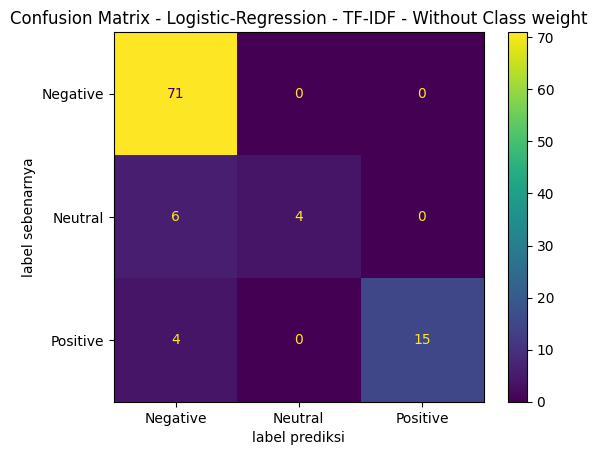

In [49]:
cm = confusion_matrix(y_test, y_pred, labels=[-1, 0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)
disp.plot()
plt.title("Confusion Matrix - Logistic-Regression - TF-IDF - Without Class weight")
plt.xlabel("label prediksi")
plt.ylabel("label sebenarnya")
plt.show()

In [50]:
print(classification_report(y_test, y_pred, labels=[-1, 0, 1],
                            target_names=["Negative", "Neutral", "Positive"], digits=4))

              precision    recall  f1-score   support

    Negative     0.8765    1.0000    0.9342        71
     Neutral     1.0000    0.4000    0.5714        10
    Positive     1.0000    0.7895    0.8824        19

    accuracy                         0.9000       100
   macro avg     0.9588    0.7298    0.7960       100
weighted avg     0.9123    0.9000    0.8881       100



<h3>IndoBERT Embedding Vectorization</h3>

In [51]:
#Catboost
import shutil

model = CatBoostClassifier(
    loss_function="MultiClass",
    eval_metric="MultiClass",
    iterations=500,
    learning_rate=0.05,
    depth=8,
    random_seed=42,
    verbose=100,
    task_type="GPU",
)

model.fit(X_train_bert,y_train,eval_set=(X_val_bert, y_val),early_stopping_rounds=50)

y_pred = model.predict(X_test_bert).ravel()

0:	learn: 1.0398341	test: 1.0440056	best: 1.0440056 (0)	total: 39.6ms	remaining: 19.7s
100:	learn: 0.1137986	test: 0.2757068	best: 0.2757068 (100)	total: 3.85s	remaining: 15.2s
200:	learn: 0.0520091	test: 0.2461901	best: 0.2461901 (200)	total: 10.3s	remaining: 15.4s
300:	learn: 0.0326780	test: 0.2369950	best: 0.2369681 (299)	total: 13.7s	remaining: 9.03s
400:	learn: 0.0231810	test: 0.2343614	best: 0.2341366 (382)	total: 17.7s	remaining: 4.36s
bestTest = 0.234125185
bestIteration = 405
Shrink model to first 406 iterations.


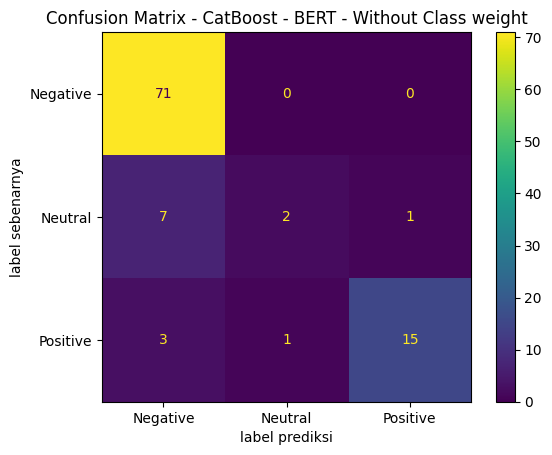

In [52]:
cm = confusion_matrix(y_test, y_pred, labels=[-1, 0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)
disp.plot()
plt.title("Confusion Matrix - CatBoost - BERT - Without Class weight")
plt.xlabel("label prediksi")
plt.ylabel("label sebenarnya")
plt.show()

In [53]:
print(classification_report(y_test, y_pred, labels=[-1, 0, 1],
                            target_names=["Negative", "Neutral", "Positive"], digits=4))

              precision    recall  f1-score   support

    Negative     0.8765    1.0000    0.9342        71
     Neutral     0.6667    0.2000    0.3077        10
    Positive     0.9375    0.7895    0.8571        19

    accuracy                         0.8800       100
   macro avg     0.8269    0.6632    0.6997       100
weighted avg     0.8671    0.8800    0.8569       100



In [54]:
#Logistic Regression
lr = LogisticRegression(max_iter=2000)
lr.fit(X_train_bert, y_train)
y_pred = lr.predict(X_test_bert).ravel()

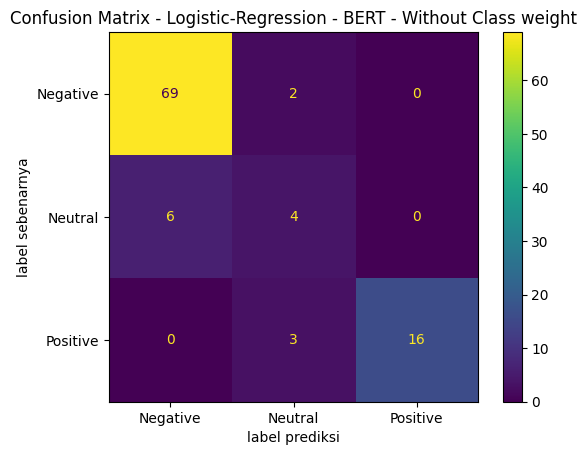

In [55]:
cm = confusion_matrix(y_test, y_pred, labels=[-1, 0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)
disp.plot()
plt.title("Confusion Matrix - Logistic-Regression - BERT - Without Class weight")
plt.xlabel("label prediksi")
plt.ylabel("label sebenarnya")
plt.show()

In [56]:
print(classification_report(y_test, y_pred, labels=[-1, 0, 1],
                            target_names=["Negative", "Neutral", "Positive"], digits=4))

              precision    recall  f1-score   support

    Negative     0.9200    0.9718    0.9452        71
     Neutral     0.4444    0.4000    0.4211        10
    Positive     1.0000    0.8421    0.9143        19

    accuracy                         0.8900       100
   macro avg     0.7881    0.7380    0.7602       100
weighted avg     0.8876    0.8900    0.8869       100



<h1>WordCloud Analysis</h1>

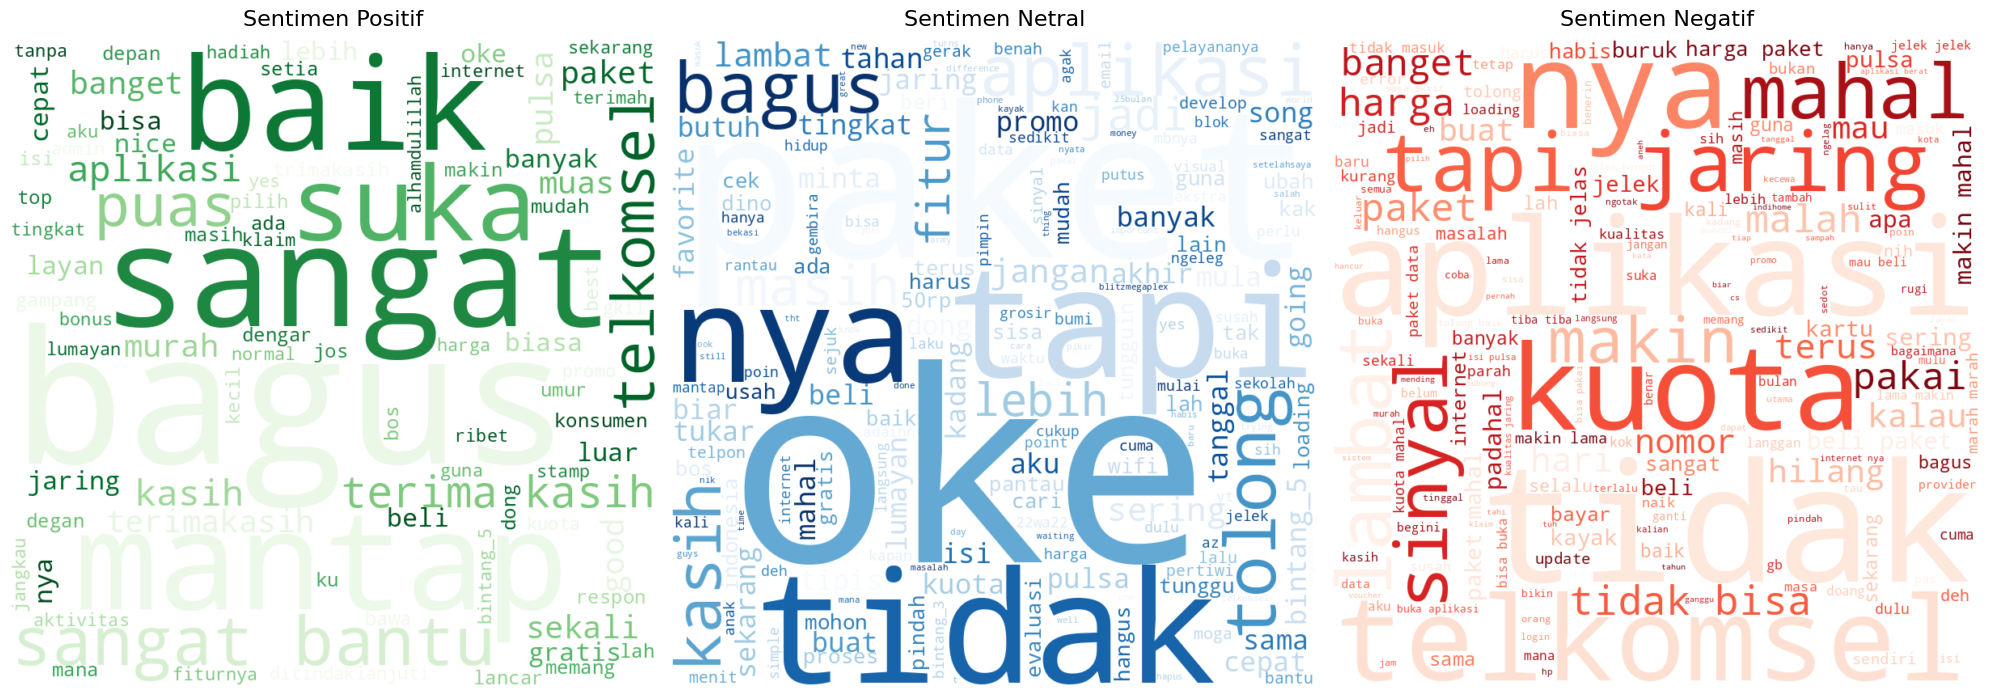

In [57]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

ulasan_positif = " ".join(target[target["target"] == 1]["ulasan_clean"])
ulasan_negatif = " ".join(target[target["target"] == -1]["ulasan_clean"])
ulasan_netral = " ".join(target[target["target"] == 0]["ulasan_clean"])

fig, axes = plt.subplots(1, 3, figsize=(20, 8))

if ulasan_positif.strip():
    wc_pos = WordCloud(width=800, height=800, background_color='white', colormap='Greens', min_font_size=10).generate(ulasan_positif)
    axes[0].imshow(wc_pos, interpolation='bilinear')
    axes[0].set_title("Sentimen Positif", fontsize=16, pad=10)
else:
    axes[0].text(0.5, 0.5, 'Tidak ada data', ha='center', va='center', fontsize=14)
axes[0].axis("off")

if ulasan_netral.strip():
    wc_neu = WordCloud(width=800, height=800, background_color='white', colormap='Blues', min_font_size=10).generate(ulasan_netral)
    axes[1].imshow(wc_neu, interpolation='bilinear')
    axes[1].set_title("Sentimen Netral", fontsize=16, pad=10)
else:
    axes[1].text(0.5, 0.5, 'Tidak ada data', ha='center', va='center', fontsize=14)
axes[1].axis("off")

if ulasan_negatif.strip():
    wc_neg = WordCloud(width=800, height=800, background_color='white', colormap='Reds', min_font_size=10).generate(ulasan_negatif)
    axes[2].imshow(wc_neg, interpolation='bilinear')
    axes[2].set_title("Sentimen Negatif", fontsize=16, pad=10)
else:
    axes[2].text(0.5, 0.5, 'Tidak ada data', ha='center', va='center', fontsize=14)
axes[2].axis("off")

plt.tight_layout()
plt.show()

<h1>Aspect-Based Sentiment Analysis (ABSA)</h1>

Untuk mendeteksi bias pada ulasan, kami membedakan ulasan yang membahas aspek **layanan internet** (jaringan, kuota, paket, harga) dari ulasan yang membahas aspek **aplikasi** (login, error, tampilan, fitur). Dengan pemisahan ini, sentimen dapat dianalisis per aspek sehingga terlihat apa yang sebenarnya dinilai oleh pengguna.

<h3>Deteksi kategori aspek (Aspect Category Detection)</h3>

Setiap ulasan diberi satu dari empat kategori dengan **kamus kata kunci**:

- **aplikasi**: menyebut aplikasi, login, OTP, update, crash, error, loading, iklan, fitur, dan sejenisnya.
- **layanan**: menyebut jaringan, sinyal, internet, kuota, paket, pulsa, harga, tarif, masa aktif, dan sejenisnya.
- **keduanya**: menyebut kata dari dua kelompok di atas.
- **umum**: tidak menyebut sasaran yang jelas (misalnya "jelek banget", "mantap").

In [70]:
URUTAN_ASPEK = ["aplikasi", "layanan", "aplikasi dan layanan", "umum"]

KATA_APLIKASI = [
    r"aplikasi\w*", r"aplikadi", r"apk\w*", r"app", r"apps", r"apl", r"my ?telkomsel",
    r"login", r"log ?in", r"log ?out", r"relog", r"otp", r"verifikasi\w*",
    r"update\w*", r"versi", r"crash", r"force ?close", r"forcecolse", r"fourclose", r"fc",
    r"keluar sendiri", r"kluar sendiri", r"menutup sendiri", r"tutup sendiri", r"terpental",
    r"ngelag", r"lag", r"nge ?hang", r"hang", r"bug", r"error", r"eror\w*", r"loading\w*",
    r"iklan\w*", r"pop ?up", r"notif\w*", r"fitur\w*", r"tampilan\w*", r"si[sk]+[ck][ck]amling",
    r"stamp", r"menu", r"tombol", r"install\w*", r"uninstall\w*",
]

FRASA_APLIKASI = (r"\b(tidak|gak|ga|gk|ngak|nggak|tdk) bisa (masuk|login|dibuka|di buka|buka)\b"
                  r"|\bgabisa (masuk|login|dibuka|di buka|buka)\b"
                  r"|\bsusah (masuk|login|dibuka|di buka|buka)\b|\bgagal (masuk|login)\b"
                  r"|\b(tidak|gak|ga|ngak|nggak) (bisa )?(terbuka|kebuka)\b"
                  r"|\bmetode pembayaran\b"
                  r"|\bpembayaran\w*( \w+){0,4} (gagal|error|eror|lemot|lambat|stuck)\b"
                  r"|\bpembayaran\w*( \w+){0,2} (tidak|gak|ga|ngak) bisa\b")

KATA_LAYANAN = [
    r"jaringan\w*", r"sinyal\w*", r"signal\w*", r"singal\w*", r"siknyal\w*", r"signyal\w*",
    r"internet\w*", r"koneksi\w*", r"cs", r"customer service",
    r"[2345]g", r"lte", r"kuota\w*", r"kouta\w*", r"quota\w*", r"paket\w*", r"pket\w*",
    r"pulsa\w*", r"harga\w*", r"mahal\w*", r"murah\w*", r"tarif\w*", r"masa aktif",
    r"hangus\w*", r"provider\w*", r"provder", r"operator\w*", r"kartu\w*", r"simpati",
    r"indihome\w*", r"telepon\w*", r"nelpon\w*", r"telfon\w*", r"sms", r"spam",
]

pola_aplikasi = re.compile(r"\b(" + "|".join(KATA_APLIKASI) + r")\b")
pola_frasa_aplikasi = re.compile(FRASA_APLIKASI)
pola_layanan = re.compile(r"\b(" + "|".join(KATA_LAYANAN) + r")\b")
# "beli paket" / "isi pulsa" hanya menyebut tindakan membeli, bukan keluhan layanan.
pola_tindakan_beli = re.compile(r"\b(beli|membeli|pembelian|isi|top ?up)\s+(paket|pulsa|kuota|kouta)\w*")


def teks_untuk_dicek(teks_asli, token_normal):
    """Gabungan teks asli (huruf kecil, tanpa simbol) dan token hasil normalisasi."""
    asli = re.sub(r"[^a-z0-9\s]", " ", str(teks_asli).lower())
    norm = " ".join(token_normal) if isinstance(token_normal, list) else ""
    return asli + " | " + norm


def tandai_aspek(teks_cek):
    ada_aplikasi = bool(pola_aplikasi.search(teks_cek) or pola_frasa_aplikasi.search(teks_cek))
    ada_layanan = bool(pola_layanan.search(pola_tindakan_beli.sub(r"\1", teks_cek)))
    if ada_aplikasi and ada_layanan:
        return "aplikasi dan layanan"
    if ada_aplikasi:
        return "aplikasi"
    if ada_layanan:
        return "layanan"
    return "umum"


# df_aspek = salinan `target` + kolom aspek. `target` sendiri tidak diubah.
# Kolom "tokens" di `target` berisi token hasil normalisasi (sebelum stopword dan stemming).
df_aspek = target.copy()
df_aspek["teks_cek"] = [teks_untuk_dicek(u, t) for u, t in zip(df_aspek["ulasan"], df_aspek["tokens"])]
df_aspek["aspek"] = df_aspek["teks_cek"].apply(tandai_aspek)

print("Jumlah ulasan per aspek:")
display(df_aspek["aspek"].value_counts().reindex(URUTAN_ASPEK, fill_value=0))
print("\nContoh per aspek:")
for a in URUTAN_ASPEK:
    contoh = df_aspek.loc[df_aspek["aspek"] == a, "ulasan"].head(2).tolist()
    for c in contoh:
        print(f"  [{a}] {c[:110]}")

Jumlah ulasan per aspek:


,count
aspek,
aplikasi,87
layanan,191
aplikasi dan layanan,81
umum,141



Contoh per aspek:
  [aplikasi] Suka kluar sendiri padahal hp ram 8 aneh nih aplikasi berat bgt kaya nanggung utang negara aja,,
  [aplikasi] Pada saat metode memilih metode pembayaran lemot pollllllllll
  [layanan] jaringan Telkomsel wilayah Agam timur sangat lelet
  [layanan] udah beli paket, tapi ngak masuk2 paketnya 👎
  [aplikasi dan layanan] maaf ya saya kurangin dulu bintang nya soal nya pket nya padah mahal semua perbaikin dulu sistem nya yg suka e
  [aplikasi dan layanan] sinyal lemot sering keluar aplikasi sendiri mau msk lg susah sungguh membagongkan
  [umum] mantap
  [umum] ok bos


<h3>Melihat aspek yang dominan untuk rating bintang 1</h3>

Karena rating bintang 1 mendominasi, kita perlu tahu apa yang dikeluhkan oleh pengguna.

Jika sebagian besar ulasan bintang 1 **hanya** mengeluhkan layanan tanpa menyebut aplikasi, maka rating aplikasi di Play Store ikut turun karena hal di luar pengalaman penggunaan aplikasi MyTelkomsel.

- **Panel kiri**: komposisi aspek pada ulasan bintang 1 berlabel negatif.
- **Panel kanan**: rata-rata rating untuk tiap aspek, dari semua ulasan.

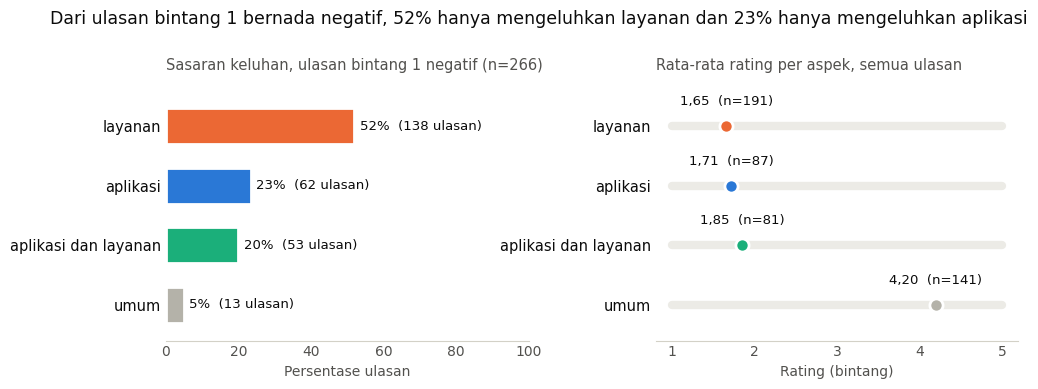

-> 51,9% hanya mengeluhkan layanan (jaringan/harga/paket) tanpa menyebut aplikasi.
-> 23,3% hanya mengeluhkan aplikasi.
-> 19,9% menyebut keduanya, 4,9% tidak menyebut sasaran yang jelas.


,bintang1_negatif,persen_bintang1_negatif,rata_rating_semua_ulasan,jumlah_semua_ulasan
aspek,,,,
layanan,138,51.9,1.65,191
aplikasi,62,23.3,1.71,87
aplikasi dan layanan,53,19.9,1.85,81
umum,13,4.9,4.20,141


In [71]:
WARNA_ASPEK = {"layanan": "#eb6834", "aplikasi": "#2a78d6", "aplikasi dan layanan": "#1baf7a", "umum": "#b4b2a9"}
URUTAN_GRAFIK = ["layanan", "aplikasi", "aplikasi dan layanan", "umum"]
TEKS, TEKS_REDUP, GARIS = "#0b0b0b", "#52514e", "#d3d1c7"
koma = lambda x, d=0: f"{x:.{d}f}".replace(".", ",")

bintang1_neg = df_aspek[(df_aspek["rating"] == 1) & (df_aspek["target"] == -1)]
jumlah_b1 = bintang1_neg["aspek"].value_counts().reindex(URUTAN_GRAFIK, fill_value=0)
porsi = jumlah_b1 / jumlah_b1.sum() * 100
rating_aspek = df_aspek.groupby("aspek")["rating"].agg(["mean", "count"]).reindex(URUTAN_GRAFIK)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"wspace": 0.35})
fig.suptitle(f"Dari ulasan bintang 1 bernada negatif, {koma(porsi["layanan"])}% hanya mengeluhkan layanan "
             f"dan {koma(porsi["aplikasi"])}% hanya mengeluhkan aplikasi",
             x=0.02, ha="left", fontsize=12.5, color=TEKS)
urutan_y = URUTAN_GRAFIK[::-1]

# Panel kiri: sasaran keluhan pada ulasan bintang 1 yang negatif
ax1.barh(urutan_y, porsi[urutan_y], height=0.6, color=[WARNA_ASPEK[a] for a in urutan_y],
         edgecolor="white", linewidth=2)
for i, a in enumerate(urutan_y):
    ax1.text(porsi[a] + 1.5, i, f"{koma(porsi[a])}%  ({jumlah_b1[a]} ulasan)",
             va="center", fontsize=9.5, color=TEKS)
ax1.set_xlim(0, 100)
ax1.set_title(f"Sasaran keluhan, ulasan bintang 1 negatif (n={len(bintang1_neg)})",
              loc="left", fontsize=10.5, color=TEKS_REDUP)
ax1.set_xlabel("Persentase ulasan", color=TEKS_REDUP)

# Panel kanan: rata-rata rating per aspek, semua ulasan
for i, a in enumerate(urutan_y):
    ax2.plot([1, 5], [i, i], color="#ecebe6", linewidth=6, solid_capstyle="round", zorder=1)
    rata, n = rating_aspek.loc[a, "mean"], rating_aspek.loc[a, "count"]
    if pd.notna(rata):
        ax2.scatter(rata, i, s=90, color=WARNA_ASPEK[a], edgecolor="white", linewidth=2, zorder=3)
        ax2.text(rata, i + 0.3, f"{koma(rata, 2)}  (n={int(n)})", ha="center", va="bottom",
                 fontsize=9.5, color=TEKS)
ax2.set_yticks(range(len(urutan_y)), urutan_y)
ax2.set_xlim(0.8, 5.2)
ax2.set_xticks([1, 2, 3, 4, 5])
ax2.set_title("Rata-rata rating per aspek, semua ulasan", loc="left", fontsize=10.5, color=TEKS_REDUP)
ax2.set_xlabel("Rating (bintang)", color=TEKS_REDUP)

for ax in (ax1, ax2):
    ax.set_ylim(-0.6, len(urutan_y) - 0.2)
    for sisi in ["top", "right", "left"]:
        ax.spines[sisi].set_visible(False)
    ax.spines["bottom"].set_color(GARIS)
    ax.tick_params(colors=TEKS_REDUP, length=0)
    ax.tick_params(axis="y", labelsize=10.5, labelcolor=TEKS)
plt.subplots_adjust(top=0.80)
plt.show()

print(f"-> {koma(porsi["layanan"], 1)}% hanya mengeluhkan layanan (jaringan/harga/paket) tanpa menyebut aplikasi.")
print(f"-> {koma(porsi["aplikasi"], 1)}% hanya mengeluhkan aplikasi.")
print(f"-> {koma(porsi["aplikasi dan layanan"], 1)}% menyebut keduanya, {koma(porsi["umum"], 1)}% tidak menyebut sasaran yang jelas.")

# Tabel angka pasti untuk laporan
display(pd.DataFrame({
    "bintang1_negatif": jumlah_b1,
    "persen_bintang1_negatif": porsi.round(1),
    "rata_rating_semua_ulasan": rating_aspek["mean"].round(2),
    "jumlah_semua_ulasan": rating_aspek["count"].fillna(0).astype(int),
}))

<h3>Komposisi aspek di tiap rating</h3>

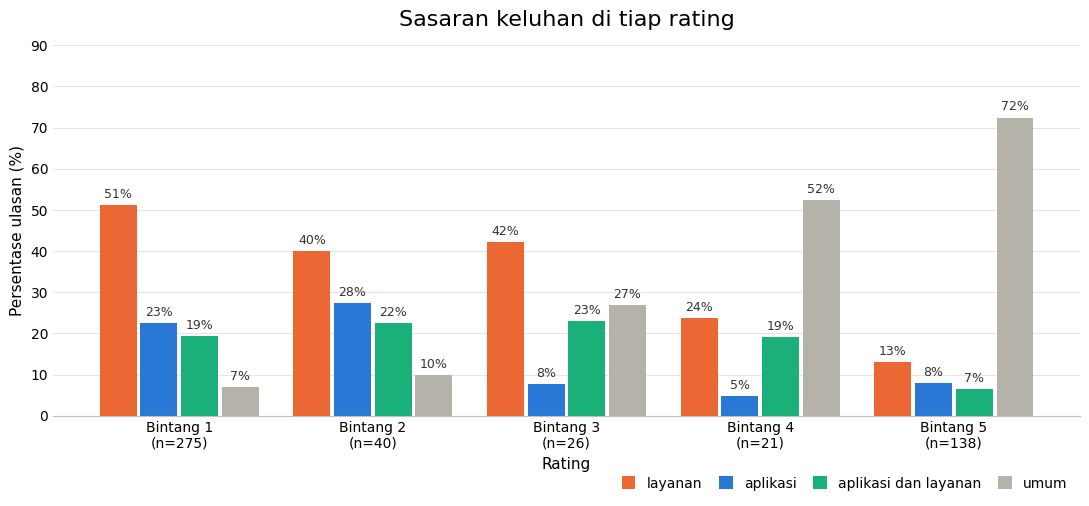

In [86]:
import numpy as np
import matplotlib.pyplot as plt

WARNA_ASPEK = {"layanan": "#eb6834", "aplikasi": "#2a78d6", "aplikasi dan layanan": "#1baf7a", "umum": "#b4b2a9"}
URUTAN_GRAFIK = ["layanan", "aplikasi", "aplikasi dan layanan", "umum"]

# Persentase aspek di tiap rating (tiap kelompok bintang = 100%)
tabel = (pd.crosstab(df_aspek["rating"], df_aspek["aspek"], normalize="index") * 100) \
    .reindex(columns=URUTAN_GRAFIK, fill_value=0).sort_index()
jumlah = df_aspek["rating"].value_counts().reindex(tabel.index)

x = np.arange(len(tabel.index))   # satu kelompok per rating
lebar = 0.19                      # lebar satu batang
jarak = 0.02                      # celah antarbatang dalam satu kelompok

fig, ax = plt.subplots(figsize=(11, 5.2))
for k, aspek in enumerate(URUTAN_GRAFIK):
    geser = (k - (len(URUTAN_GRAFIK) - 1) / 2) * (lebar + jarak)
    batang = ax.bar(x + geser, tabel[aspek], width=lebar, color=WARNA_ASPEK[aspek], label=aspek, zorder=2)
    ax.bar_label(batang, labels=[f"{v:.0f}%" for v in tabel[aspek]], padding=3, fontsize=9, color="#333333")

ax.set_xticks(x, [f"Bintang {r}\n(n={n})" for r, n in zip(tabel.index, jumlah)])
ax.set_ylim(0, np.ceil((tabel.values.max() + 8) / 10) * 10)
ax.set_ylabel("Persentase ulasan (%)", fontsize=11)
ax.set_xlabel("Rating", fontsize=11)
ax.set_title("Sasaran keluhan di tiap rating", fontsize=16, pad=14)

ax.yaxis.grid(True, color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
for sisi in ["top", "right", "left"]:
    ax.spines[sisi].set_visible(False)
ax.spines["bottom"].set_color("#bfbfbf")
ax.tick_params(length=0, labelsize=10)
ax.legend(ncol=4, loc="upper right", bbox_to_anchor=(1, -0.13), frameon=False, fontsize=10,
          handlelength=1, handleheight=1, columnspacing=1.2)
plt.tight_layout()
plt.show()

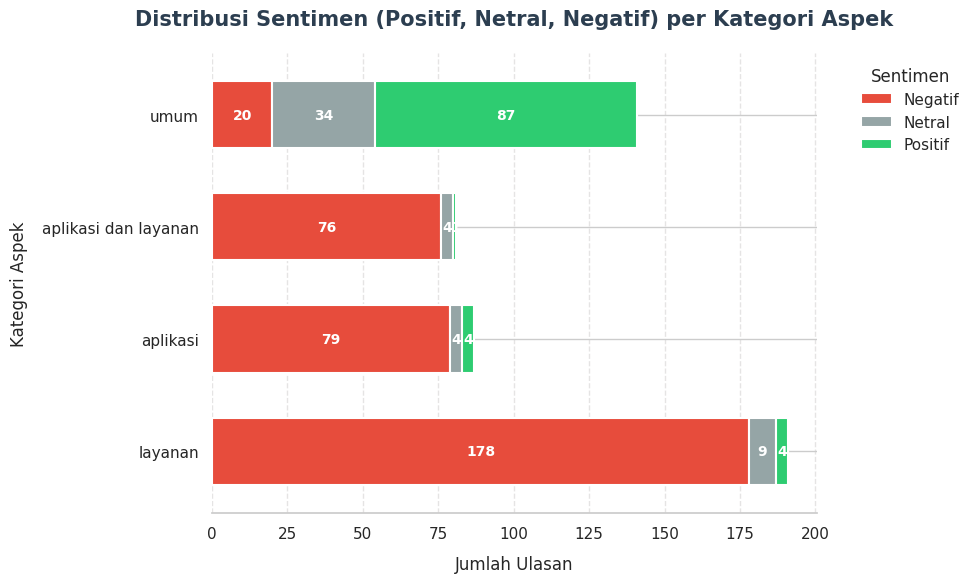

label_sentimen_aspek,Negatif,Netral,Positif
aspek,,,
layanan,178,9,4
aplikasi,79,4,4
aplikasi dan layanan,76,4,1
umum,20,34,87


In [95]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Memetakan nilai sentimen angka kembali ke label teks untuk kemudahan visualisasi
nama_sentimen_map = {-1: 'Negatif', 0: 'Netral', 1: 'Positif'}
df_aspek['label_sentimen_aspek'] = df_aspek['target'].map(nama_sentimen_map)

# Membuat crosstab antara Aspek dan Sentimen
tabel_aspek_sentimen = pd.crosstab(df_aspek['aspek'], df_aspek['label_sentimen_aspek'])

# Mengurutkan baris dan kolom agar visualisasinya konsisten
urutan_aspek_plot = ['layanan', 'aplikasi', 'aplikasi dan layanan', 'umum']
urutan_sentimen_plot = ['Negatif', 'Netral', 'Positif']

tabel_aspek_sentimen = tabel_aspek_sentimen.reindex(index=urutan_aspek_plot, columns=urutan_sentimen_plot, fill_value=0)

# Skema warna yang elegan dan representatif
# Merah/Oranye untuk Negatif, Abu-abu untuk Netral, Hijau untuk Positif
warna_sentimen = ['#e74c3c', '#95a5a6', '#2ecc71']

# Membuat Stacked Bar Chart
fig, ax = plt.subplots(figsize=(10, 6))
tabel_aspek_sentimen.plot(kind='barh', stacked=True, color=warna_sentimen, ax=ax, width=0.6, edgecolor='white', linewidth=1.5)

# Menambahkan anotasi angka jumlah review di dalam batang grafik
for p in ax.patches:
    width = p.get_width()
    if width > 0:  # Hanya tampilkan label jika jumlah review > 0
        x = p.get_x() + width / 2
        y = p.get_y() + p.get_height() / 2
        ax.annotate(f'{int(width)}',
                    (x, y),
                    ha='center',
                    va='center',
                    color='white',
                    fontsize=10,
                    weight='bold')

# Mengatur judul dan label sumbu
ax.set_title('Distribusi Sentimen (Positif, Netral, Negatif) per Kategori Aspek', fontsize=15, pad=20, weight='bold', color='#2c3e50')
ax.set_xlabel('Jumlah Ulasan', fontsize=12, labelpad=10)
ax.set_ylabel('Kategori Aspek', fontsize=12, labelpad=10)

# Mempercantik tampilan grid dan bingkai
ax.xaxis.grid(True, linestyle='--', alpha=0.5, color='#cccbca')
ax.set_axisbelow(True)
sns.despine(left=True, top=True, right=True)

# Menyesuaikan legenda
ax.legend(title='Sentimen', bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False, fontsize=11, title_fontsize=12)

plt.tight_layout()
plt.show()

# Menampilkan tabel angka untuk detail presisi
display(tabel_aspek_sentimen)

<h3>Aspect Category Sentiment Analysis (ACSA)</h3>

**Aspect Category Sentiment Analysis (ACSA)** menentukan sentimen untuk **setiap kategori aspek** dalam satu ulasan. Contoh: *"Aplikasinya enak dipakai, tapi sinyalnya sering hilang"* → **aplikasi: positif**, **layanan: negatif**. Label tunggal per ulasan tidak bisa menangkap perbedaan ini.

| Aspek ulasan (A1) | Sentimen aplikasi | Sentimen layanan |
|---|---|---|
| `aplikasi` | label manusia (`target`) | tidak dibahas |
| `layanan` | tidak dibahas | label manusia (`target`) |
| `keduanya` | dari klausa yang menyebut aplikasi | dari klausa yang menyebut layanan |
| `umum` | tidak dibahas | tidak dibahas |

Untuk ulasan `keduanya`:
1. Ulasan dipecah menjadi klausa pada kata penghubung kontras (*tapi, tetapi, namun, padahal, sayangnya, sedangkan, walaupun, meskipun, hanya saja*) dan tanda akhir kalimat (`.`, `!`, `?`, `;`).
2. Setiap klausa diproses dengan **praproses yang sama** dengan notebook (`tokenize` → `normalize_token` → stopword → `stem_word`), dideteksi aspeknya dengan A1, lalu sentimennya diprediksi oleh Logistic Regression + TF-IDF + class weight (`lr_aspek`).
3. Jika satu aspek muncul di beberapa klausa, sentimennya adalah tanda dari rata-rata prediksi klausa.
4. Jika sebuah aspek tidak punya klausa sendiri, sentimennya memakai label manusia untuk seluruh ulasan.


In [84]:
lr_aspek = LogisticRegression(max_iter=2000, class_weight="balanced")
lr_aspek.fit(X_train, y_train)

POLA_PEMISAH_KLAUSA = re.compile(
    r"\b(?:tapi|tetapi|tp|namun|padahal|sayangnya|sedangkan|walaupun|walau|meskipun|meski|"
    r"biarpun|hanya saja|but)\b|[.!?;\n]+")
NAMA_SENTIMEN = {-1: "negatif", 0: "netral", 1: "positif"}


def pecah_klausa(teks):
    bagian = POLA_PEMISAH_KLAUSA.split(str(teks).lower())
    return [b.strip() for b in bagian if b and re.search(r"[a-z]", b)]


def praproses_klausa(klausa):
    """Praproses yang sama dengan notebook: tokenize -> normalisasi -> stopword -> stemming."""
    token_normal = normalize_token(tokenize(klausa))
    token_bersih = [t for t in token_normal if t.lower() not in stopwords_sastrawi]
    teks_bersih = " ".join(s for s in (stem_word(t) for t in token_bersih) if s.strip())
    return token_normal, teks_bersih


def prediksi_klausa(teks_bersih):
    vektor = vectorizer.transform([teks_bersih])
    if vektor.nnz == 0:          # tidak ada satu pun kata yang dikenal model
        return None
    return int(lr_aspek.predict(vektor.toarray())[0])


def acsa_satu_ulasan(baris):
    hasil = {"sentimen_aplikasi": np.nan, "sentimen_layanan": np.nan,
             "sumber_aplikasi": "", "sumber_layanan": "", "rincian_klausa": ""}
    aspek = baris["aspek"]

    if aspek in ("aplikasi", "layanan"):
        hasil[f"sentimen_{aspek}"] = baris["target"]
        hasil[f"sumber_{aspek}"] = "label manusia"
        return pd.Series(hasil)
    if aspek != "aplikasi dan layanan":
        return pd.Series(hasil)

    per_aspek = {"aplikasi": [], "layanan": []}
    rincian = []
    for klausa in pecah_klausa(baris["ulasan"]):
        token_normal, teks_bersih = praproses_klausa(klausa)
        aspek_klausa = tandai_aspek(teks_untuk_dicek(klausa, token_normal))
        if aspek_klausa not in ("aplikasi", "layanan"):
            continue                         # klausa umum atau menyebut dua aspek sekaligus
        s = prediksi_klausa(teks_bersih)
        if s is None:
            continue
        per_aspek[aspek_klausa].append(s)
        rincian.append(f"[{aspek_klausa}:{NAMA_SENTIMEN[s]}] {klausa}")

    for a in ("aplikasi", "layanan"):
        if per_aspek[a]:
            hasil[f"sentimen_{a}"] = int(np.sign(np.mean(per_aspek[a])))
            hasil[f"sumber_{a}"] = "model per klausa"
        else:
            hasil[f"sentimen_{a}"] = baris["target"]
            hasil[f"sumber_{a}"] = "label manusia (tidak bisa dipisah)"
    hasil["rincian_klausa"] = " || ".join(rincian)
    return pd.Series(hasil)


kolom_acsa = ["sentimen_aplikasi", "sentimen_layanan", "sumber_aplikasi", "sumber_layanan", "rincian_klausa"]
df_aspek = df_aspek.drop(columns=kolom_acsa, errors="ignore")   # aman jika sel ini dijalankan ulang
df_aspek = df_aspek.join(df_aspek.apply(acsa_satu_ulasan, axis=1))

keduanya = df_aspek[df_aspek["aspek"] == "aplikasi dan layanan"]
print(f"Ulasan 'aplikasi dan layanan': {len(keduanya)}")
print(f"  aplikasi dari model per klausa: {(keduanya['sumber_aplikasi'] == 'model per klausa').sum()}")
print(f"  layanan  dari model per klausa: {(keduanya['sumber_layanan'] == 'model per klausa').sum()}")

print("\nSentimen aplikasi (baris) vs sentimen layanan (kolom) pada ulasan 'aplikasi dan layanan':")
display(pd.crosstab(keduanya["sentimen_aplikasi"].map(NAMA_SENTIMEN),
                    keduanya["sentimen_layanan"].map(NAMA_SENTIMEN), margins=True, margins_name="total"))

print("\nContoh hasil pemecahan klausa:")
for _, r in keduanya[keduanya["rincian_klausa"].str.count(r"\|\|") >= 1].head(5).iterrows():
    print(f"- {r['ulasan'][:140]}")
    print(f"  -> {r['rincian_klausa'][:220]}")

Ulasan 'aplikasi dan layanan': 81
  aplikasi dari model per klausa: 35
  layanan  dari model per klausa: 42

Sentimen aplikasi (baris) vs sentimen layanan (kolom) pada ulasan 'aplikasi dan layanan':


sentimen_layanan,negatif,netral,positif,total
sentimen_aplikasi,,,,
negatif,70,2,3,75
netral,2,3,0,5
positif,1,0,0,1
total,73,5,3,81



Contoh hasil pemecahan klausa:
- udh saya beli paket simpati tapi saya unduh lagi apk ini,malah susah masuk no hp udh bener padahal mah
  -> [layanan:netral] udh saya beli paket simpati || [aplikasi:negatif] saya unduh lagi apk ini,malah susah masuk no hp udh bener
- 1. paket mahal 2. paket selalu berubah-ubah 3. paket di bagi-bagi tidak All in 4. aplikasi sebentar-sebentar selalu update 5. kadang jaringa
  -> [layanan:negatif] paket mahal 2 || [layanan:negatif] paket selalu berubah-ubah 3 || [layanan:negatif] paket di bagi-bagi tidak all in 4 || [aplikasi:negatif] aplikasi sebentar-sebentar selalu update 5 || [layanan:netral]
- kenapa gak bisa tukar pakai koin kenapa harus pake sisa pulsa juga .., dan kenapa paket internet buat game tapi gak bisa di pake main game m
  -> [layanan:negatif] kenapa gak bisa tukar pakai koin kenapa harus pake sisa pulsa juga || [layanan:negatif] , dan kenapa paket internet buat game || [aplikasi:negatif] udah tau gak bisa ke pake kalau ke aplikasi
- Sang

<h3>Seberapa banyak rating rendah disebabkan oleh layanan, bukan aplikasi?</h3>

Dengan sentimen per aspek, setiap ulasan dikelompokkan:

| Kelompok | Arti |
|---|---|
| **Layanan negatif, aplikasi tidak disebut** | Keluhan murni soal jaringan/harga/paket |
| **Layanan negatif, aplikasi netral/positif** | Bukti terkuat bias: pengguna puas atau biasa saja dengan aplikasi, tetapi tetap memberi rating rendah |
| **Keduanya negatif** | Aplikasi dan layanan sama-sama dikeluhkan |
| **Aplikasi negatif saja** | Keluhan yang memang ditujukan ke aplikasi |
| **Tidak menyebut sasaran** | Aspek `umum` |
| **Tidak ada aspek negatif** | Aspek disebut, tetapi tidak ada yang bernada negatif |

**Porsi bias layanan** = dua kelompok pertama, yaitu rating rendah yang diberikan tanpa keluhan terhadap aplikasi.

Persentase kelompok per rating:


kelompok_bias,n,"Layanan negatif, aplikasi tidak disebut","Layanan negatif, aplikasi netral/positif",Keduanya negatif,Aplikasi negatif saja,Tidak menyebut sasaran,Tidak ada aspek negatif
rating,,,,,,,
1,275,50.2,0.7,17.8,23.3,6.9,1.1
2,40,40.0,0.0,22.5,25.0,10.0,2.5
3,26,34.6,0.0,19.2,11.5,26.9,7.7
4,21,14.3,4.8,4.8,4.8,52.4,19.0
5,138,8.7,0.0,4.3,4.3,72.5,10.1


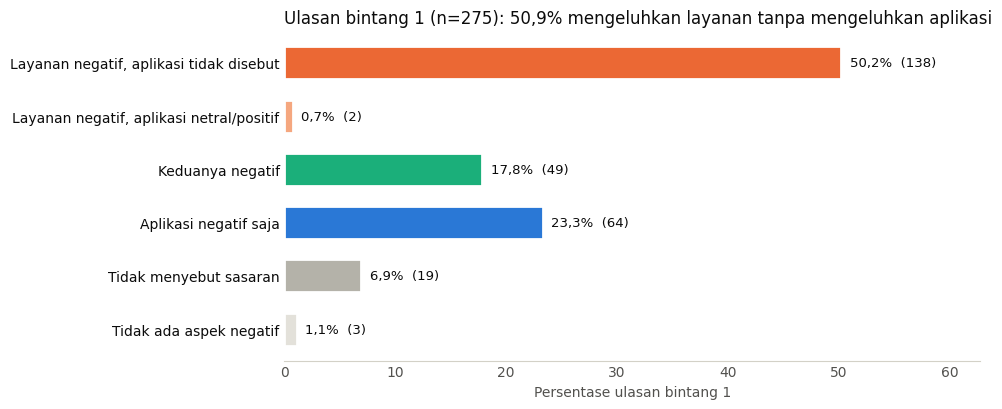

-> Porsi bias layanan pada bintang 1: 50,9%
   (2 ulasan bahkan bernada netral/positif terhadap aplikasinya.)
-> Keluhan yang memang ditujukan ke aplikasi (aplikasi saja + keduanya): 41,1%


In [87]:
URUTAN_BIAS = ["Layanan negatif, aplikasi tidak disebut", "Layanan negatif, aplikasi netral/positif",
               "Keduanya negatif", "Aplikasi negatif saja", "Tidak menyebut sasaran", "Tidak ada aspek negatif"]
WARNA_BIAS = ["#eb6834", "#f5a77f", "#1baf7a", "#2a78d6", "#b4b2a9", "#e3e1da"]


def kelompok_bias(baris):
    sa, sl = baris["sentimen_aplikasi"], baris["sentimen_layanan"]
    if baris["aspek"] == "umum":
        return "Tidak menyebut sasaran"
    if sl == -1 and sa == -1:
        return "Keduanya negatif"
    if sl == -1:
        return URUTAN_BIAS[0] if pd.isna(sa) else URUTAN_BIAS[1]
    if sa == -1:
        return "Aplikasi negatif saja"
    return "Tidak ada aspek negatif"


df_aspek["kelompok_bias"] = df_aspek.apply(kelompok_bias, axis=1)

# Tabel semua rating (setiap baris = 100%)
tabel_bias = (pd.crosstab(df_aspek["rating"], df_aspek["kelompok_bias"], normalize="index") * 100) \
    .reindex(columns=URUTAN_BIAS, fill_value=0).round(1)
tabel_bias.insert(0, "n", df_aspek["rating"].value_counts().reindex(tabel_bias.index))
print("Persentase kelompok per rating:")
display(tabel_bias)

# Grafik untuk ulasan bintang 1
b1 = df_aspek[df_aspek["rating"] == 1]
jumlah_b1_bias = b1["kelompok_bias"].value_counts().reindex(URUTAN_BIAS, fill_value=0)
persen_b1_bias = jumlah_b1_bias / len(b1) * 100

fig, ax = plt.subplots(figsize=(10, 4.2))
urutan_y_bias = URUTAN_BIAS[::-1]
ax.barh(urutan_y_bias, persen_b1_bias[urutan_y_bias], height=0.62,
        color=WARNA_BIAS[::-1], edgecolor="white", linewidth=2)
for i, k in enumerate(urutan_y_bias):
    ax.text(persen_b1_bias[k] + 0.8, i, f"{persen_b1_bias[k]:.1f}%  ({jumlah_b1_bias[k]})".replace(".", ","),
            va="center", fontsize=9.5, color="#0b0b0b")
porsi_bias = persen_b1_bias[URUTAN_BIAS[:2]].sum()
ax.set_title(f"Ulasan bintang 1 (n={len(b1)}): {porsi_bias:.1f}% mengeluhkan layanan tanpa mengeluhkan aplikasi"
             .replace(".", ","), loc="left", fontsize=12, color="#0b0b0b")
ax.set_xlim(0, max(persen_b1_bias.max() * 1.25, 10))
ax.set_xlabel("Persentase ulasan bintang 1", color="#52514e")
for sisi in ["top", "right", "left"]:
    ax.spines[sisi].set_visible(False)
ax.spines["bottom"].set_color("#d3d1c7")
ax.tick_params(colors="#52514e", length=0)
ax.tick_params(axis="y", labelcolor="#0b0b0b")
plt.tight_layout()
plt.show()

print(f"-> Porsi bias layanan pada bintang 1: {porsi_bias:.1f}%".replace(".", ","))
print(f"   ({jumlah_b1_bias[URUTAN_BIAS[1]]} ulasan bahkan bernada netral/positif terhadap aplikasinya.)")
print(f"-> Keluhan yang memang ditujukan ke aplikasi (aplikasi saja + keduanya): "
      f"{persen_b1_bias[['Aplikasi negatif saja', 'Keduanya negatif']].sum():.1f}%".replace(".", ","))